# Task 28: Outlier Detection
**Track:** AI & ML Track  
**Objective:** Understand basic outlier detection through visualization by creating a box plot for a numerical variable and identifying potential outliers.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Enable inline plotting for Jupyter Notebook
%matplotlib inline

### Step 1: Create a Sample Dataset
We will generate a sample **Employee Salary Dataset** containing numerical salary values (in USD), including deliberate high and low outliers to demonstrate outlier detection via box plots.

In [2]:
# Set random seed for reproducibility
np.random.seed(42)

# Generate a normal salary distribution between $45,000 and $95,000 (50 records)
normal_salaries = np.random.normal(loc=70000, scale=10000, size=50)

# Introduce extreme outliers (e.g., interns/part-time at $18,000 & $22,000; executives at $160,000 & $175,000)
outliers = np.array([18000, 22000, 160000, 175000])

# Combine and form final dataset
all_salaries = np.concatenate([normal_salaries, outliers])

# Create pandas DataFrame
df = pd.DataFrame({
    'Employee_ID': range(1, len(all_salaries) + 1),
    'Salary': all_salaries
})

# Display the first few rows
print(df.head())
print(f"\nTotal records in dataset: {len(df)}")

   Employee_ID        Salary
0            1  74967.141530
1            2  68617.356988
2            3  76476.885381
3            4  85230.298564
4            5  67658.466253

Total records in dataset: 54


### Step 2: Create a Box Plot for Outlier Visualization
A box plot summarizes data distribution using quartiles:
* **Median ($Q_2$):** The middle value of the dataset.
* **First Quartile ($Q_1$):** The 25th percentile.
* **Third Quartile ($Q_3$):** The 75th percentile.
* **Interquartile Range ($IQR$):** $Q_3 - Q_1$
* **Whiskers:** Typically extend to $Q_1 - 1.5 \times IQR$ and $Q_3 + 1.5 \times IQR$. Points falling outside these boundaries are displayed individually as potential outliers.

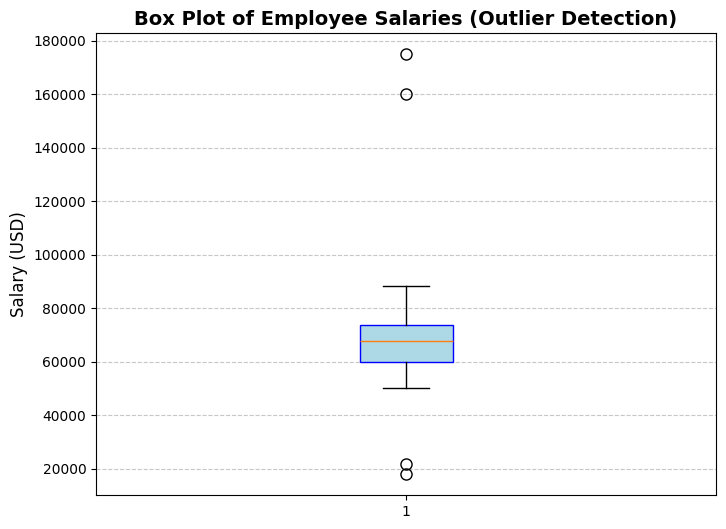

In [3]:
# Set figure size
plt.figure(figsize=(8, 6))

# Create the box plot using plt.boxplot()
plt.boxplot(df['Salary'], patch_artist=True, 
            boxprops=dict(facecolor='lightblue', color='blue'),
            flierprops=dict(marker='o', color='red', markersize=8))

# Add titles and labels
plt.title('Box Plot of Employee Salaries (Outlier Detection)', fontsize=14, fontweight='bold')
plt.ylabel('Salary (USD)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the plot
plt.show()

In [4]:
# Calculating exact bounds using the IQR method to verify visualization findings
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter potential outliers
potential_outliers = df[(df['Salary'] < lower_bound) | (df['Salary'] > upper_bound)]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")
print("\nIdentified Potential Outliers:")
print(potential_outliers)

Q1: 60133.71
Q3: 73676.78
IQR: 13543.07
Lower Bound: 39819.09
Upper Bound: 93991.39

Identified Potential Outliers:
    Employee_ID    Salary
50           51   18000.0
51           52   22000.0
52           53  160000.0
53           54  175000.0


### Step 3: Explanation of Findings
* **Visual Observation:** In the generated box plot, individual red circular markers appear well beyond the upper and lower whiskers. These points represent values significantly higher or lower than the central spread of salaries.
* **Analytical Confirmation:** Using the Interquartile Range (IQR) method, data points falling below the lower bound or above the upper bound are flagged as anomalies.
* **Domain Context:** In real-world data analysis, outliers should be investigated rather than discarded blindly. Some may be data entry errors (e.g., mistyped extra zeros), while others represent genuine domain extremes (such as top-tier executive salaries or part-time stipends).

## Interview Questions & Answers

### 1. What is an outlier?
* **Answer:** An outlier is an observation point that lies an abnormal distance from other values in a random sample from a population. Outliers can be caused by measurement or recording errors (e.g., typographical mistakes), data corruption, or they can represent true extreme variability within the underlying population (e.g., high-income earners or rare fraudulent transactions).

### 2. How can a box plot help identify outliers?
* **Answer:** A box plot provides a visual summary of a dataset's distribution using quartiles. The box encapsulates the middle 50% of the data (from $Q_1$ to $Q_3$), while the whiskers typically extend to $1.5 \times IQR$ beyond the hinges. Any data points lying beyond the whiskers are plotted individually as distinct points (fliers), making potential outliers instantly recognizable visually.

### 3. Should every outlier be removed?
* **Answer:** No, outliers should **never** be automatically removed without investigation. While erroneous outliers caused by sensor malfunction or data entry mistakes should be cleaned or dropped, valid outliers often carry critical information (e.g., peak web traffic spikes, rare medical anomalies, or fraud detection signals). Removing valid extremes can introduce sampling bias and cause models to overlook important edge cases.